# ML Assignment 2 – Classification Models, Evaluation & Model Export
**M.Tech (AIML) – Machine Learning | BITS Pilani WILP**

 BITS ID - 2026AJ05611

**Dataset:** UCI Dry Bean Dataset (ID 602) – 13,611 instances, 16 numeric shape features, 7 bean classes (multi-class)



## 1. Imports

In [32]:
#%pip install --upgrade "numpy>=2" pandas scikit-learn matplotlib seaborn joblib openpyxl

In [33]:
import os
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
print("Libraries loaded")

Libraries loaded


## 2. Configuration


In [34]:
CANDIDATE_PATHS = [
    "Dry_Bean_Dataset.xlsx",
    "DryBeanDataset/Dry_Bean_Dataset.xlsx",
    "data/Dry_Bean_Dataset.xlsx",
    "Dry_Bean_Dataset.csv",
    "data/Dry_Bean_Dataset.csv",
]
TARGET_COL = "Class"

TEST_SIZE = 0.2
RANDOM_STATE = 42
MODEL_DIR = "model"
TEST_CSV = "test_data.csv"

os.makedirs(MODEL_DIR, exist_ok=True)

## 3. Load Dataset

In [35]:
def load_dry_bean():
    for path in CANDIDATE_PATHS:
        if os.path.exists(path):
            print("Loading from", path)
            # reading .xlsx needs the 'openpyxl' package
            return pd.read_excel(path) if path.endswith(".xlsx") else pd.read_csv(path)
    print("Local file not found - downloading via ucimlrepo ...")
    from ucimlrepo import fetch_ucirepo
    ds = fetch_ucirepo(id=602)
    return pd.concat([ds.data.features, ds.data.targets], axis=1)

df = load_dry_bean()
df.columns = [str(c).strip() for c in df.columns]
assert TARGET_COL in df.columns, f"Target column '{TARGET_COL}' not found: {df.columns.tolist()}"
df[TARGET_COL] = df[TARGET_COL].astype(str).str.strip()

# Keep a CSV copy of the full dataset in the repo (handy for the README / reproducibility)
os.makedirs("data", exist_ok=True)
df.to_csv("data/Dry_Bean_Dataset.csv", index=False)

N_RAW_ROWS = len(df)
print("Shape:", df.shape)
df.head()

Loading from Dry_Bean_Dataset.xlsx
Shape: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


## 4. Exploratory Data Analysis

In [36]:
n_features = df.shape[1] - 1
n_instances = df.shape[0]
print(f"Features : {n_features}  (minimum required: 12) -> {'OK' if n_features >= 12 else 'TOO FEW'}")
print(f"Instances: {n_instances} (minimum required: 500) -> {'OK' if n_instances >= 500 else 'TOO FEW'}")
print("\nData types:")
print(df.dtypes.value_counts())
print("\nMissing values (top 10):")
print(df.isnull().sum().sort_values(ascending=False).head(10))
print("\nDuplicate rows:", df.duplicated().sum())

Features : 16  (minimum required: 12) -> OK
Instances: 13611 (minimum required: 500) -> OK

Data types:
float64    14
int64       2
str         1
Name: count, dtype: int64

Missing values (top 10):
Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
dtype: int64

Duplicate rows: 68


In [37]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860153
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRation,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677


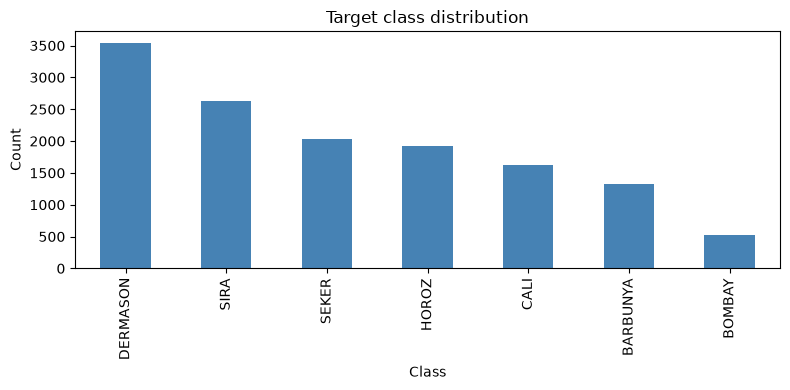

Class
DERMASON    0.261
SIRA        0.194
SEKER       0.149
HOROZ       0.142
CALI        0.120
BARBUNYA    0.097
BOMBAY      0.038
Name: proportion, dtype: float64

The classes are imbalanced (e.g. DERMASON vs BOMBAY), so weighted Precision/Recall/F1 and MCC
are more informative than accuracy alone.


In [38]:
fig, ax = plt.subplots(figsize=(8, 4))
df[TARGET_COL].value_counts().plot(kind="bar", ax=ax, color="steelblue")
ax.set_title("Target class distribution")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()
print(df[TARGET_COL].value_counts(normalize=True).round(3))
print("\nThe classes are imbalanced (e.g. DERMASON vs BOMBAY), so weighted Precision/Recall/F1 and MCC")
print("are more informative than accuracy alone.")

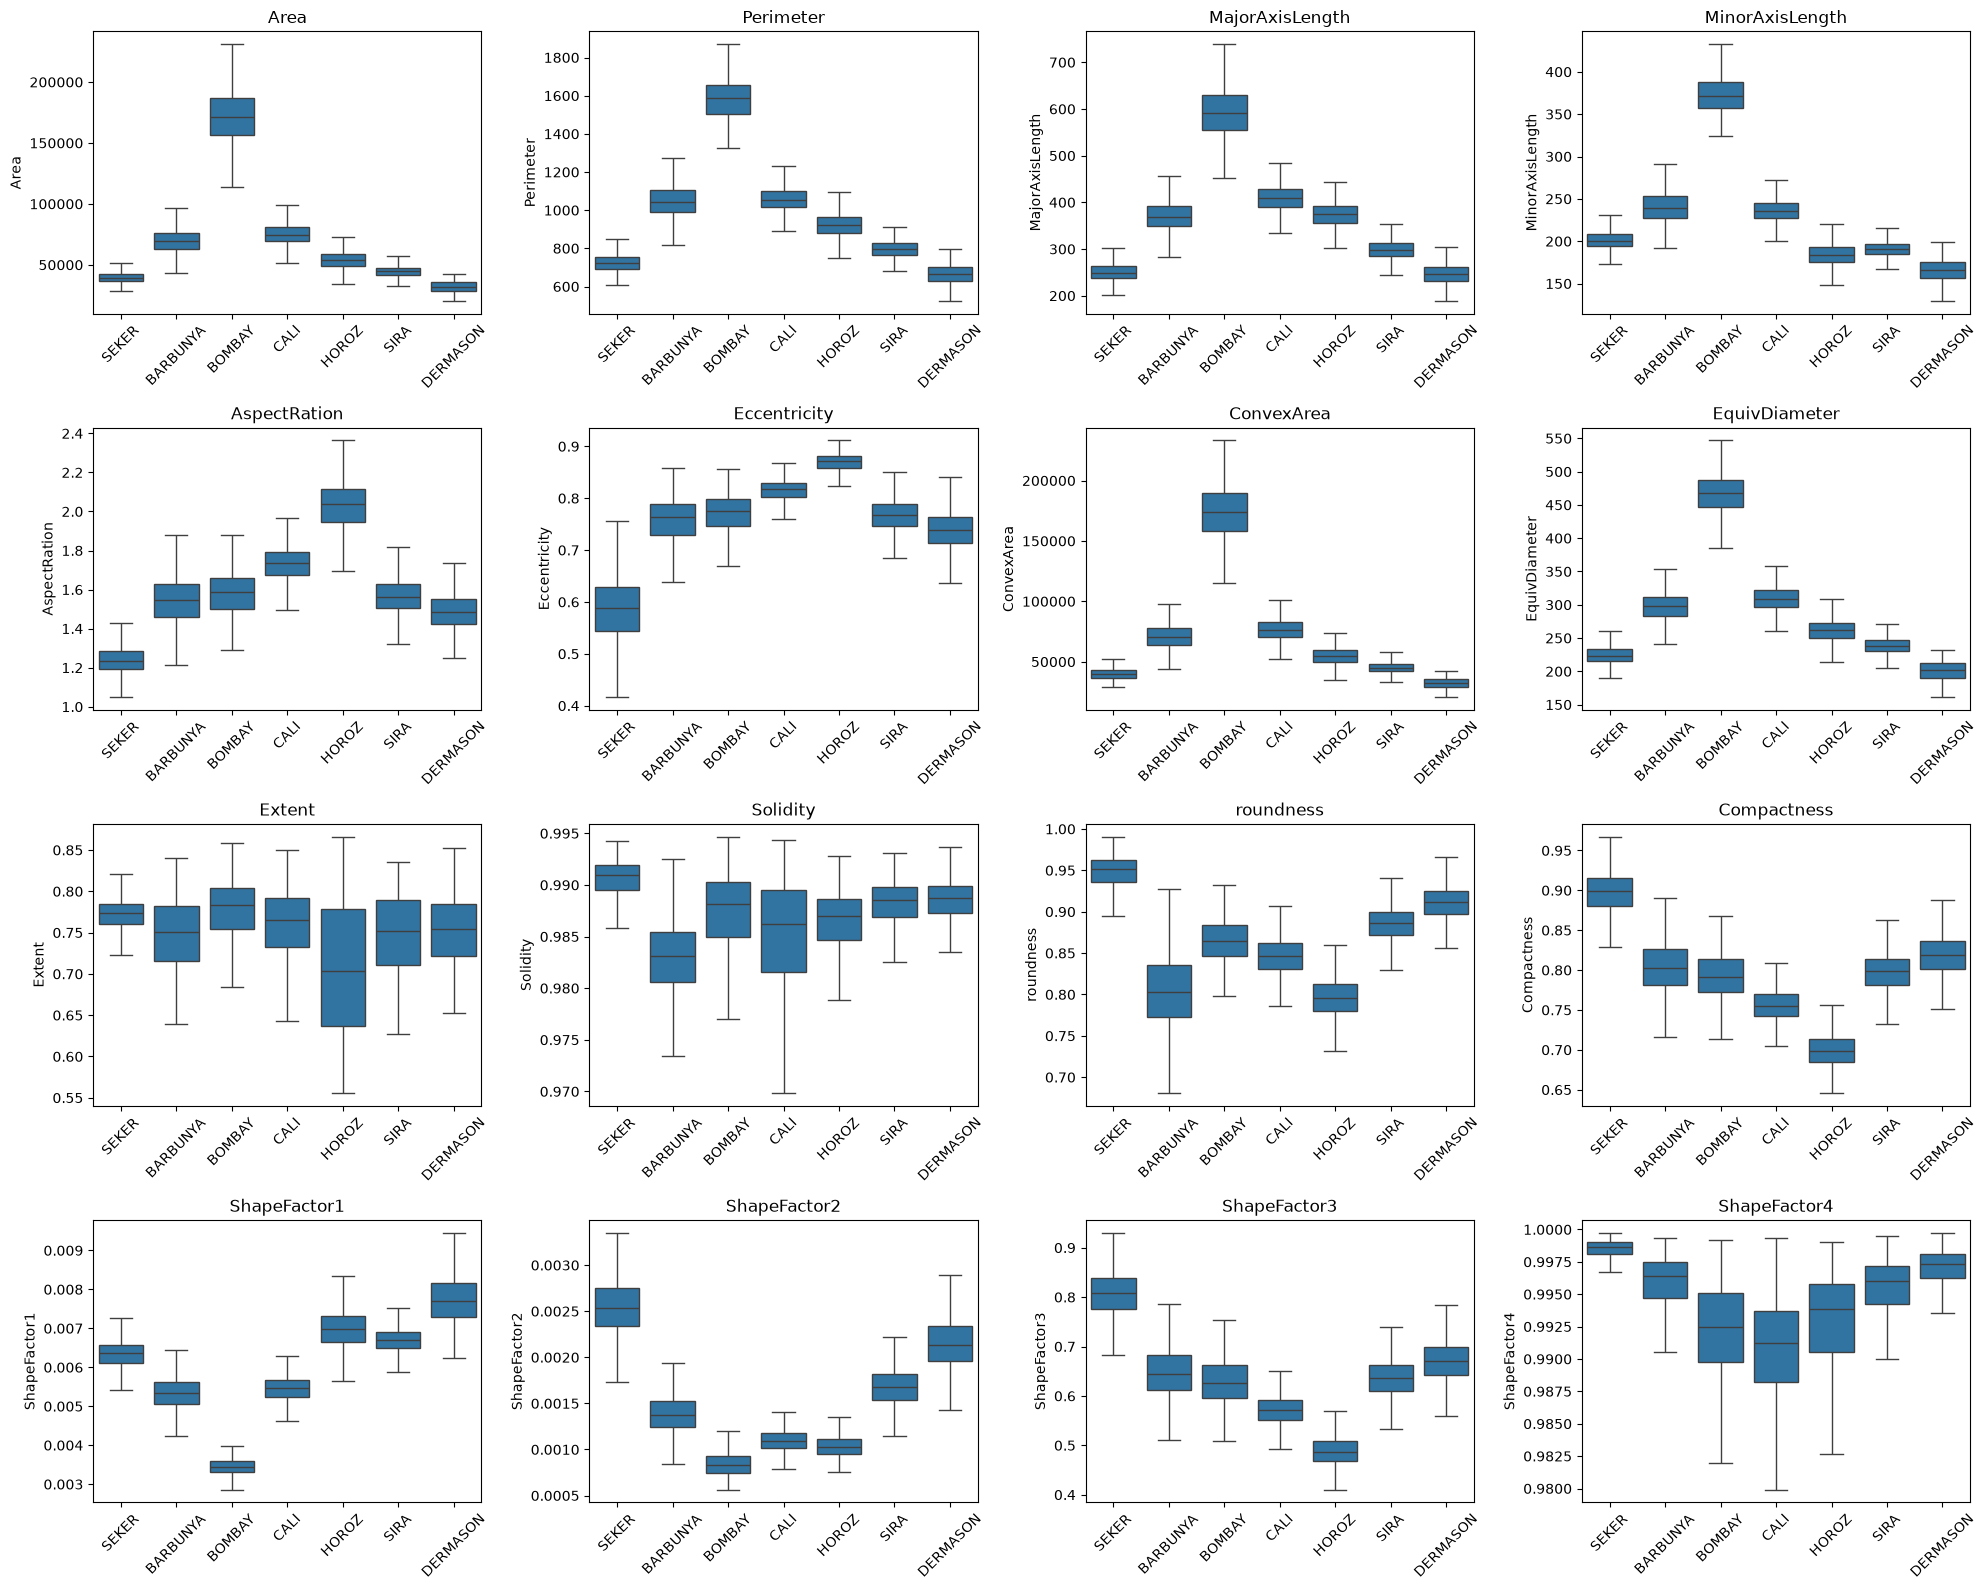

In [39]:
# Distribution of each shape feature per bean class
features = [c for c in df.columns if c != TARGET_COL]
fig, axes = plt.subplots(4, 4, figsize=(20, 16))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(data=df, x=TARGET_COL, y=col, ax=ax, showfliers=False)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

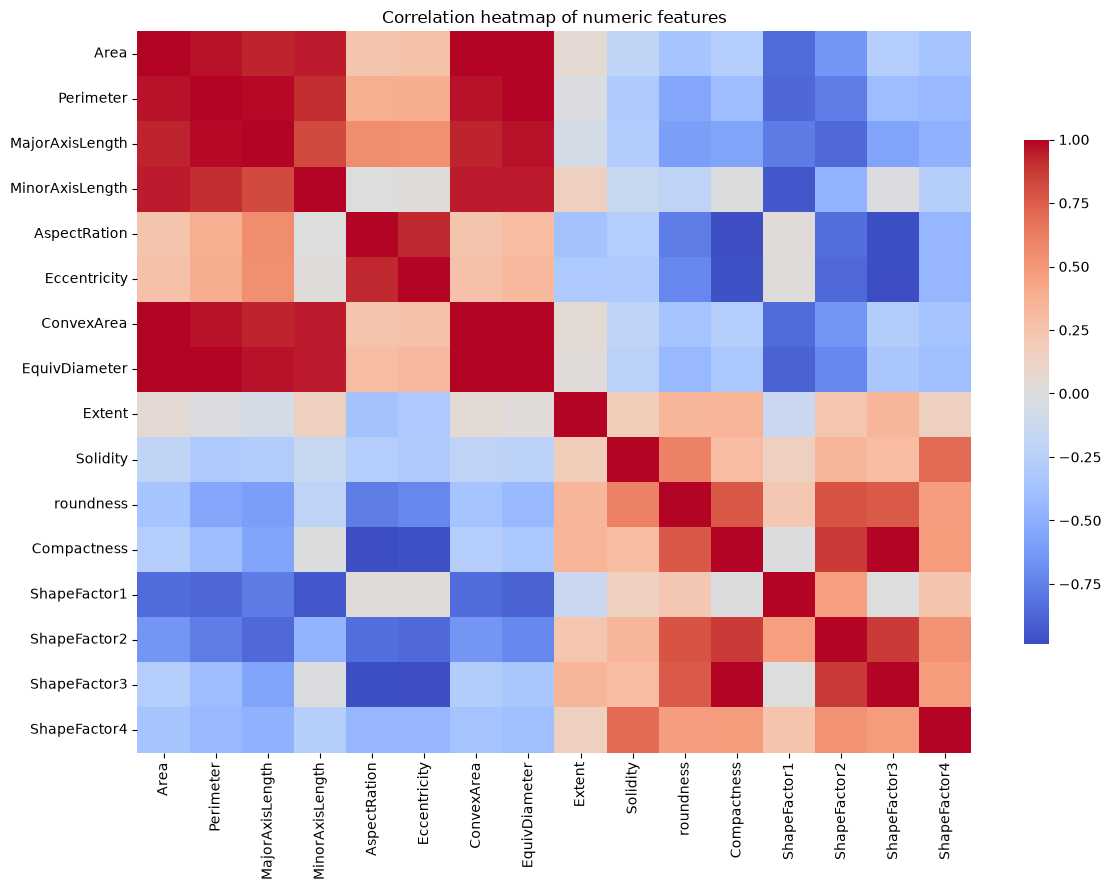

Feature pairs with |correlation| > 0.95:
Area             ConvexArea         1.000
Compactness      ShapeFactor3       0.999
Perimeter        EquivDiameter      0.991
AspectRation     Compactness        0.988
ConvexArea       EquivDiameter      0.985
Area             EquivDiameter      0.985
Eccentricity     ShapeFactor3       0.981
AspectRation     ShapeFactor3       0.979
Perimeter        MajorAxisLength    0.977
Eccentricity     Compactness        0.970
Perimeter        ConvexArea         0.968
Area             Perimeter          0.967
MajorAxisLength  EquivDiameter      0.962
Area             MinorAxisLength    0.952
MinorAxisLength  ConvexArea         0.951
dtype: float64


In [40]:
num_df = df.drop(columns=[TARGET_COL]).select_dtypes(include=np.number)
if num_df.shape[1] > 1:
    plt.figure(figsize=(12, 9))
    sns.heatmap(num_df.corr(), cmap="coolwarm", center=0, cbar_kws={"shrink": 0.7})
    plt.title("Correlation heatmap of numeric features")
    plt.tight_layout()
    plt.show()

# Strongly correlated pairs (size features such as Area / ConvexArea / Perimeter / EquivDiameter overlap heavily)
corr = num_df.corr().abs()
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
             .stack().sort_values(ascending=False))
print("Feature pairs with |correlation| > 0.95:")
print(pairs[pairs > 0.95].round(3))

## 5. Preprocessing & Train/Test Split

In [41]:
df = df.drop_duplicates().dropna(subset=[TARGET_COL]).reset_index(drop=True)

X = df.drop(columns=[TARGET_COL])
y_raw = df[TARGET_COL]

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_raw.astype(str))
class_names = list(label_encoder.classes_)
n_classes = len(class_names)
IS_BINARY = n_classes == 2
print("Classes:", dict(enumerate(class_names)))
print("Problem type:", "Binary" if IS_BINARY else f"Multi-class ({n_classes} classes)")

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()
print(f"Numeric features: {len(num_cols)} | Categorical features: {len(cat_cols)}")

Classes: {0: 'BARBUNYA', 1: 'BOMBAY', 2: 'CALI', 3: 'DERMASON', 4: 'HOROZ', 5: 'SEKER', 6: 'SIRA'}
Problem type: Multi-class (7 classes)
Numeric features: 16 | Categorical features: 0


In [42]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape)

# Save raw test split (features + original target labels) for the Streamlit app
test_df = X_test.copy()
test_df[TARGET_COL] = label_encoder.inverse_transform(y_test)
test_df.to_csv(TEST_CSV, index=False)
print(f"Saved {TEST_CSV} with {len(test_df)} rows")

Train: (10834, 16) | Test: (2709, 16)
Saved test_data.csv with 2709 rows


In [43]:
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer(
    [("num", numeric_pipe, num_cols), ("cat", categorical_pipe, cat_cols)],
    sparse_threshold=0,   # dense output (needed by GaussianNB)
)

## 6. Define the 5 Classifiers
Each model is wrapped in a `Pipeline` with the preprocessor, so the saved `.pkl` file can take **raw** test data directly (no separate scaling step in the app).
Scaling matters a lot here: `Area` is in the tens of thousands while `ShapeFactor1` is around 0.007, so KNN, SVM and Logistic Regression would be dominated by the size features without it.

Since this is a 7-class problem: AUC is computed one-vs-rest (weighted), and Precision/Recall/F1 use weighted averaging. SVM with `probability=True` takes a minute or two on ~11k training rows.

In [44]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=10, min_samples_leaf=5, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=7, weights="distance"),
    "Naive Bayes": GaussianNB(),
    "Support Vector Machine": SVC(kernel="rbf", C=1.0, probability=True, random_state=RANDOM_STATE),
}

pipelines = {name: Pipeline([("prep", preprocessor), ("clf", clf)]) for name, clf in models.items()}

## 7. Train & Evaluate

In [45]:
def evaluate(model, X_eval, y_eval):
    y_pred = model.predict(X_eval)
    y_proba = model.predict_proba(X_eval)
    avg = "binary" if IS_BINARY else "weighted"
    if IS_BINARY:
        auc = roc_auc_score(y_eval, y_proba[:, 1])
    else:
        auc = roc_auc_score(y_eval, y_proba, multi_class="ovr", average="weighted")
    return {
        "Accuracy": accuracy_score(y_eval, y_pred),
        "AUC": auc,
        "Precision": precision_score(y_eval, y_pred, average=avg, zero_division=0),
        "Recall": recall_score(y_eval, y_pred, average=avg, zero_division=0),
        "F1": f1_score(y_eval, y_pred, average=avg, zero_division=0),
        "MCC": matthews_corrcoef(y_eval, y_pred),
    }, y_pred

results, predictions = {}, {}
for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    results[name], predictions[name] = evaluate(pipe, X_test, y_test)
    print(f"Trained & evaluated: {name}")

Trained & evaluated: Logistic Regression
Trained & evaluated: Decision Tree
Trained & evaluated: KNN
Trained & evaluated: Naive Bayes
Trained & evaluated: Support Vector Machine


## 8. Comparison Table

In [46]:
metrics_df = pd.DataFrame(results).T.round(4)
metrics_df.index.name = "ML Model Name"
metrics_df.to_csv(os.path.join(MODEL_DIR, "metrics_summary.csv"))
metrics_df.style.highlight_max(axis=0, color="lightgreen").format("{:.4f}")

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9192,0.9934,0.9197,0.9192,0.9193,0.9023
Decision Tree,0.9070,0.9729,0.9075,0.9070,0.9071,0.8875
KNN,0.9136,0.9835,0.9144,0.9136,0.9138,0.8956
Naive Bayes,0.8970,0.9899,0.8997,0.8970,0.8972,0.8762
Support Vector Machine,0.9210,0.9933,0.9214,0.9210,0.9211,0.9045


In [47]:
# Markdown version - paste directly into README.md
try:
    print(metrics_df.to_markdown())
except ImportError:  # to_markdown needs the 'tabulate' package
    print("| ML Model Name | " + " | ".join(metrics_df.columns) + " |")
    print("|---" * (len(metrics_df.columns) + 1) + "|")
    for idx, row in metrics_df.iterrows():
        print(f"| {idx} | " + " | ".join(f"{v:.4f}" for v in row) + " |")

| ML Model Name          |   Accuracy |    AUC |   Precision |   Recall |     F1 |    MCC |
|:-----------------------|-----------:|-------:|------------:|---------:|-------:|-------:|
| Logistic Regression    |     0.9192 | 0.9934 |      0.9197 |   0.9192 | 0.9193 | 0.9023 |
| Decision Tree          |     0.907  | 0.9729 |      0.9075 |   0.907  | 0.9071 | 0.8875 |
| KNN                    |     0.9136 | 0.9835 |      0.9144 |   0.9136 | 0.9138 | 0.8956 |
| Naive Bayes            |     0.897  | 0.9899 |      0.8997 |   0.897  | 0.8972 | 0.8762 |
| Support Vector Machine |     0.921  | 0.9933 |      0.9214 |   0.921  | 0.9211 | 0.9045 |


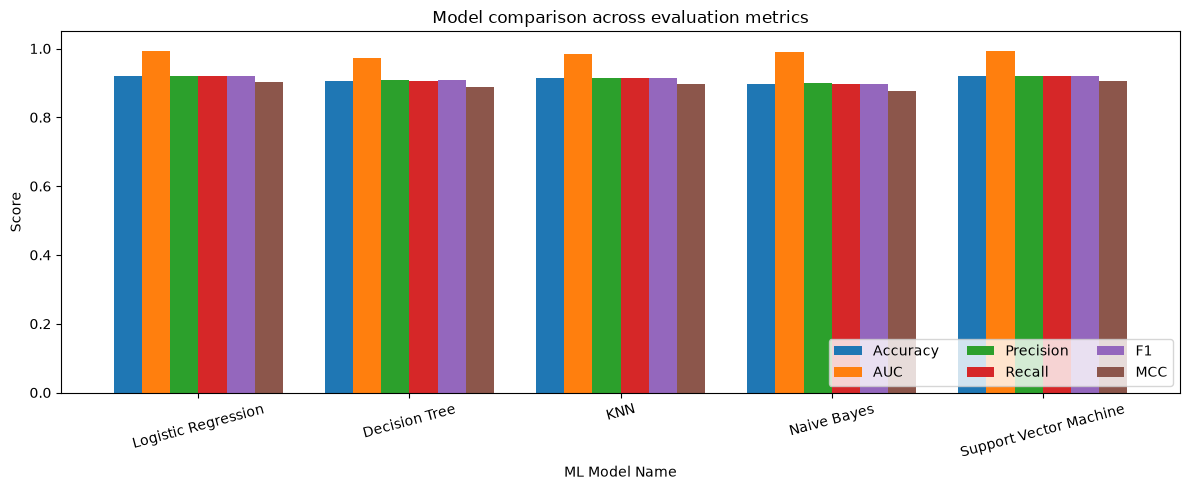

In [48]:
ax = metrics_df.plot(kind="bar", figsize=(12, 5), width=0.8)
ax.set_title("Model comparison across evaluation metrics")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.legend(loc="lower right", ncol=3)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 9. Confusion Matrices & Classification Reports

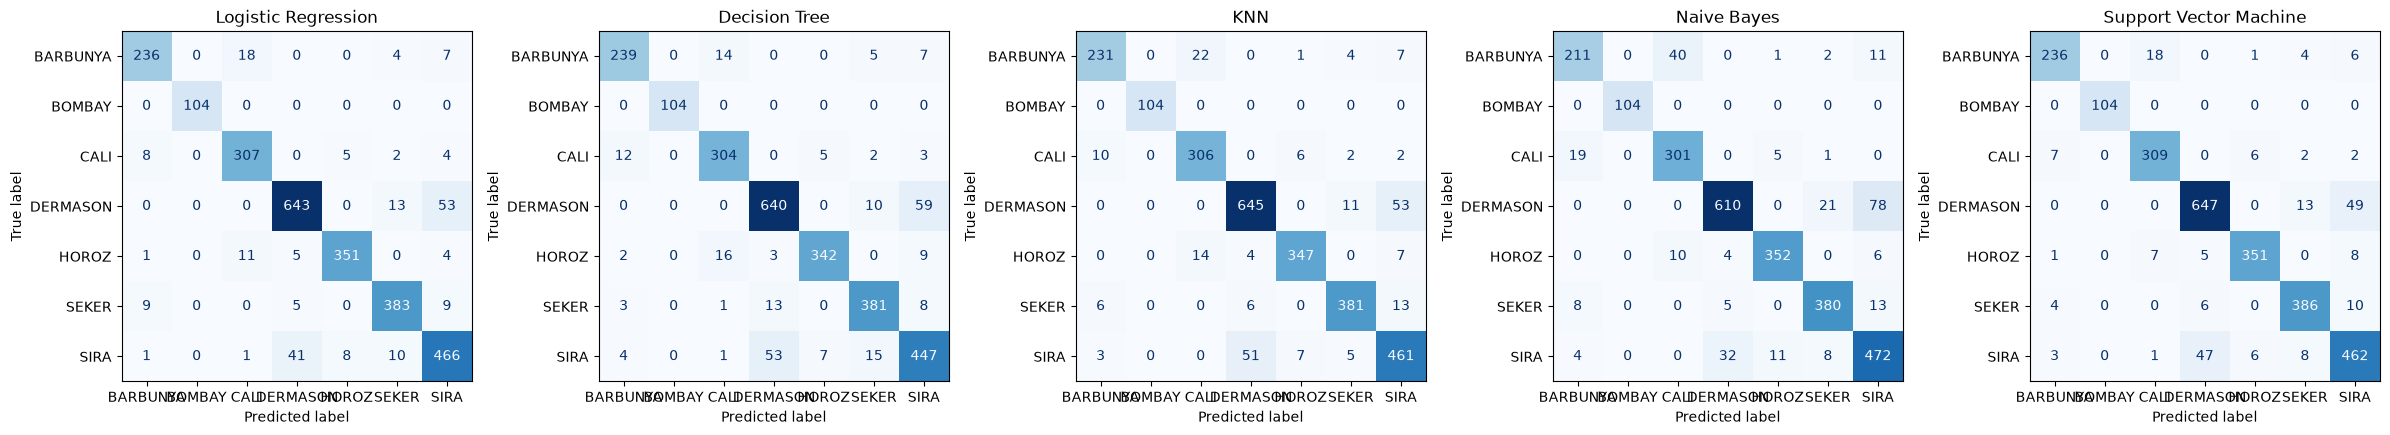

In [49]:
fig, axes = plt.subplots(1, 5, figsize=(24, 4.5))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [50]:
for name, y_pred in predictions.items():
    print("=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

Logistic Regression
              precision    recall  f1-score   support

    BARBUNYA     0.9255    0.8906    0.9077       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.9110    0.9417    0.9261       326
    DERMASON     0.9265    0.9069    0.9166       709
       HOROZ     0.9643    0.9435    0.9538       372
       SEKER     0.9296    0.9433    0.9364       406
        SIRA     0.8582    0.8843    0.8710       527

    accuracy                         0.9192      2709
   macro avg     0.9307    0.9300    0.9302      2709
weighted avg     0.9197    0.9192    0.9193      2709

Decision Tree
              precision    recall  f1-score   support

    BARBUNYA     0.9192    0.9019    0.9105       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.9048    0.9325    0.9184       326
    DERMASON     0.9027    0.9027    0.9027       709
       HOROZ     0.9661    0.9194    0.9421       372
       SEKER     0.9225    0.9384    0.9304 

## 10. Save Models & Preprocessing Artifacts

In [51]:
file_map = {}
for name, pipe in pipelines.items():
    fname = name.lower().replace(" ", "_") + ".pkl"
    joblib.dump(pipe, os.path.join(MODEL_DIR, fname))
    file_map[name] = fname

joblib.dump(label_encoder, os.path.join(MODEL_DIR, "label_encoder.pkl"))

metadata = {
    "target_column": TARGET_COL,
    "feature_columns": X.columns.tolist(),
    "numeric_columns": num_cols,
    "categorical_columns": cat_cols,
    "class_names": class_names,
    "is_binary": IS_BINARY,
    "model_files": file_map,
}
with open(os.path.join(MODEL_DIR, "metadata.json"), "w") as f:
    json.dump(metadata, f, indent=2)

print("Saved files in", MODEL_DIR, ":")
for f in sorted(os.listdir(MODEL_DIR)):
    print("  -", f)

Saved files in model :
  - decision_tree.pkl
  - knn.pkl
  - label_encoder.pkl
  - logistic_regression.pkl
  - metadata.json
  - metrics_summary.csv
  - naive_bayes.pkl
  - support_vector_machine.pkl


## 11. Sanity Check – Reload Saved Models on `test_data.csv`


In [52]:
test_loaded = pd.read_csv(TEST_CSV)
meta = json.load(open(os.path.join(MODEL_DIR, "metadata.json")))
le = joblib.load(os.path.join(MODEL_DIR, "label_encoder.pkl"))

X_chk = test_loaded[meta["feature_columns"]]
y_chk = le.transform(test_loaded[meta["target_column"]].astype(str))

check = {}
for name, fname in meta["model_files"].items():
    m = joblib.load(os.path.join(MODEL_DIR, fname))
    check[name], _ = evaluate(m, X_chk, y_chk)

check_df = pd.DataFrame(check).T.round(4)
print("Reloaded metrics match training-session metrics:",
      np.allclose(check_df.values, metrics_df.values))
check_df

Reloaded metrics match training-session metrics: True


,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.9192,0.9934,0.9197,0.9192,0.9193,0.9023
Decision Tree,0.9070,0.9729,0.9075,0.9070,0.9071,0.8875
KNN,0.9136,0.9835,0.9144,0.9136,0.9138,0.8956
Naive Bayes,0.8970,0.9899,0.8997,0.8970,0.8972,0.8762
Support Vector Machine,0.9210,0.9933,0.9214,0.9210,0.9211,0.9045


## 12. Ranking 

In [53]:
rank_df = metrics_df.rank(ascending=False).astype(int)
rank_df["Mean Rank"] = rank_df.mean(axis=1).round(2)
rank_df = rank_df.sort_values("Mean Rank")
print("Best model by mean rank:", rank_df.index[0])
rank_df

Best model by mean rank: Support Vector Machine


,Accuracy,AUC,Precision,Recall,F1,MCC,Mean Rank
ML Model Name,,,,,,,
Support Vector Machine,1,2,1,1,1,1,1.17
Logistic Regression,2,1,2,2,2,2,1.83
KNN,3,4,3,3,3,3,3.17
Decision Tree,4,5,4,4,4,4,4.17
Naive Bayes,5,3,5,5,5,5,4.67
